In [125]:
from huggingface_hub import hf_hub_download
import pandas as pd
import numpy as np
pd.options.display.max_columns=30

In [3]:
#%cd ..

In [4]:
import retail_configs

In [5]:
repo = "Dingdong-Inc/FreshRetailNet-50K"
train_path = hf_hub_download(repo_id=repo, filename="data/train.parquet", repo_type="dataset")
eval_path  = hf_hub_download(repo_id=repo, filename="data/eval.parquet",  repo_type="dataset")


In [6]:
train_full = pd.read_parquet(train_path)
eval_full = pd.read_parquet(eval_path)   


In [7]:
train_full["dt"] = pd.to_datetime(train_full["dt"])
eval_full["dt"] = pd.to_datetime(eval_full["dt"])

In [8]:
train_full.shape, eval_full.shape

((4500000, 19), (350000, 19))

In [9]:
train_full.groupby(["store_id", "product_id"]).size().describe()

count    50000.0
mean        90.0
std          0.0
min         90.0
25%         90.0
50%         90.0
75%         90.0
max         90.0
dtype: float64

- Reduce Sample Size: use a subset of top categories for the demo

In [10]:
top5_category = (train_full.groupby("first_category_id")
      .agg(rows=("sale_amount", "size"),
           products=("product_id", "nunique"),
           mean_sales=("sale_amount", "mean"),
           stockout_rate=("stock_hour6_22_cnt", lambda s: (s > 0).mean()))
      .sort_values("rows", ascending=False)).head(5)

In [11]:
top5_category

,rows,products,mean_sales,stockout_rate
first_category_id,,,,
4,979920,95,1.183621,0.428271
16,645930,90,0.731225,0.514497
20,497970,75,1.284182,0.436472
29,314640,10,1.467059,0.651290
8,259650,44,0.698997,0.373861


- pick category 29 and assume as bread, 16 as meat, and 4 as vegetables

In [12]:
retail_configs.selected_categories

[29, 16, 4]

In [13]:
train_df = train_full.query(f"first_category_id.isin({retail_configs.selected_categories})")

In [14]:
train_df.shape

(1940490, 19)

In [15]:
eval_df = eval_full.query(f"first_category_id.isin({retail_configs.selected_categories})")

In [16]:
eval_df.shape

(150927, 19)

- combine train and eval in order to construct lag features from sale amount

In [162]:
train_df["split"] = "train"
eval_df["split"] = "eval"
full = (pd.concat([train_df, eval_df], ignore_index=True)
          .sort_values(["store_id", "product_id", "dt"])
          .reset_index(drop=True))

In [150]:
full.shape

(2091417, 20)

In [151]:
train_df.sale_amount.max(), train_df.sale_amount.min(), train_df.stock_hour6_22_cnt.max()

(np.float64(27.0), np.float64(0.0), np.int32(16))

In [152]:
def denormalize_sales(df, sales_cols, multiply_factor=10):
    for c in sales_cols:
        df[c+"_denormalized"] = df[c]*multiply_factor
    return df

In [163]:
full_df = denormalize_sales(full, ["sale_amount", "hours_sale"])
full_df.sale_amount_denormalized = full_df.sale_amount_denormalized.round().astype(int)

In [154]:
full_df.head(3)

,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,split,sale_amount_denormalized,hours_sale_denormalized
0,0,0,2,29,78,82,4,2024-03-28,0.5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5, ...",13,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, ...",0.882,0,1,1.6999,15.48,73.54,1.97,train,5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.0, ..."
1,0,0,2,29,78,82,4,2024-03-29,1.3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",5,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882,0,1,3.0190,15.08,76.56,1.71,train,13,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,0,0,2,29,78,82,4,2024-03-30,5.3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.882,1,1,2.0942,15.91,76.47,1.73,train,53,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


- check how many rows are out of stock for 8 to 16hours from 6:00 to 22:00

In [155]:
full_df.query("stock_hour6_22_cnt==16").shape, full_df.query("stock_hour6_22_cnt>8&stock_hour6_22_cnt<16").shape,

((57508, 22), (256178, 22))

In [156]:
full_df.query("stock_hour6_22_cnt>8&stock_hour6_22_cnt<16").sale_amount_denormalized.mean(), full_df.query("stock_hour6_22_cnt<9").sale_amount_denormalized.mean()

(np.float64(8.39088836668254), np.float64(11.575255198902422))

- when out of stock fewer than 16 hours, naively scale by a factor, proportional to in-stock hours and capped at x1.6
- when out of stock for whole 16 hours, replace sale_amount_denormalized with the last valid sale


In [164]:
full_df["sale_amount_recovered"] = full_df["sale_amount_denormalized"].astype(float)
full_df["dmd_censored"] = full_df["stock_hour6_22_cnt"] > 0

In [ ]:
in_stock_hours = 16 - full_df["stock_hour6_22_cnt"]  
factor = (16 / in_stock_hours.clip(lower=9) * 0.9).clip(lower=1.0)        # cap at 1.6x
mask_ = (full_df["stock_hour6_22_cnt"] > 0) & (full_df["stock_hour6_22_cnt"] < 16)
full_df.loc[mask_, "sale_amount_recovered"] = full_df.loc[mask_, "sale_amount_denormalized"]*factor[mask_]


In [166]:
mask_16h = full_df["stock_hour6_22_cnt"] == 16
filled = full_df["sale_amount_recovered"].mask(mask_16h).groupby([full_df["store_id"], full_df["product_id"]]).ffill()
full_df.loc[mask_16h, "sale_amount_recovered"] = np.maximum(filled[mask_16h].fillna(full_df["sale_amount_denormalized"][mask_16h]), full_df["sale_amount_denormalized"][mask_16h])
full_df["sale_amount_recovered"] = full_df["sale_amount_recovered"].round().astype(int)


- example where sales during full day out of stock, is replaced by sales on the previous valid day

In [167]:
full_df.query("store_id==0&product_id==18&stock_hour6_22_cnt>8&stock_hour6_22_cnt<16").set_index("dt").tail()

,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,split,sale_amount_denormalized,hours_sale_denormalized,sale_amount_recovered,dmd_censored
dt,,,,,,,,,,,,,,,,,,,,,,,
2024-06-18,0,0,6,4,28,142,18,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",12,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, ...",1.0,0,0,13.2459,26.28,82.25,1.57,train,2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",3,True
2024-06-19,0,0,6,4,28,142,18,0.5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5, ...",13,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, ...",1.0,0,0,14.2063,25.66,83.20,1.64,train,5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.0, ...",8,True
2024-06-30,0,0,6,4,28,142,18,1.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",9,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, ...",1.0,1,0,6.4410,28.28,78.61,1.40,eval,12,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",19,True
2024-07-01,0,0,6,4,28,142,18,0.7,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.0, ...",12,"[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, ...",1.0,0,0,7.1287,28.66,77.61,1.39,eval,7,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, ...",11,True
2024-07-02,0,0,6,4,28,142,18,0.8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.2, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,0,0,4.7765,30.12,75.34,1.45,eval,8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 2.0, ...",13,True


<Axes: xlabel='dt'>

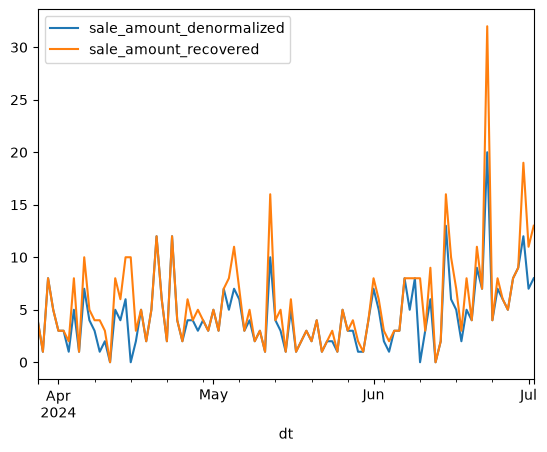

In [168]:
full_df.query("store_id==0&product_id==18").set_index("dt")[["sale_amount_denormalized", "sale_amount_recovered"]].plot()

- now add assumed category name, shelf life, price, and cost from config to selected categories

In [169]:
cat_df = (pd.DataFrame.from_dict(retail_configs.CATEGORY_CONFIG, orient="index")
            .rename_axis("first_category_id")
            .reset_index())

In [170]:
cat_df

,first_category_id,category_name,shelf_life,price,cost
0,29,bread,1,2.0,0.8
1,16,meat,3,6.0,4.0
2,4,vegetables,5,2.5,1.5
3,20,fruit,7,3.0,1.8


In [171]:
full_df = full_df.merge(cat_df, on="first_category_id", how="left")

In [172]:
full_df.shape

(2091417, 28)

- add lag features 
- use last 14 days of training data as Calibration set for computing the conformal correction
- split into train, cal, eval

In [173]:
train_df["dt"].max(), eval_df.dt.min(), eval_df.dt.max()

(Timestamp('2024-06-25 00:00:00'),
 Timestamp('2024-06-26 00:00:00'),
 Timestamp('2024-07-02 00:00:00'))

In [174]:
grp_sale = full_df.groupby(["store_id", "product_id"])["sale_amount_recovered"]
full_df["lag_1"]   = grp_sale.shift(1)                                       # yesterday
full_df["lag_7"]   = grp_sale.shift(7) 
full_df["mean_7"]  = grp_sale.transform(lambda s: s.shift(1).rolling(7,  min_periods=4).mean())
full_df["mean_28"] = grp_sale.transform(lambda s: s.shift(1).rolling(28, min_periods=14).mean())
full_df["std_7"]   = grp_sale.transform(lambda s: s.shift(1).rolling(7,  min_periods=4).std())

In [175]:
val_start = train_df["dt"].max() - pd.Timedelta(days=retail_configs.CAL_DAYS - 1)

train_df_ = full_df[full_df["dt"] < val_start]
val_df_   = full_df[(full_df["dt"] >= val_start) & (full_df["split"] == "train")]
eval_df_     = full_df[full_df["split"] == "eval"]


In [176]:
for name, df in [("train", train_df_), ("val", val_df_), ("eval", eval_df_)]:
    print(f"{name:8s} {df['dt'].min().date()} → {df['dt'].max().date()}  "
          f"{df['dt'].nunique():3d} days  {len(df):,} rows")

train    2024-03-28 → 2024-06-11   76 days  1,638,636 rows
val      2024-06-12 → 2024-06-25   14 days  301,854 rows
eval     2024-06-26 → 2024-07-02    7 days  150,927 rows


In [ ]:
#train_df_.to_parquet("data/train.parquet", index=False)
#val_df_.to_parquet("data/val.parquet", index=False)
#eval_df_.to_parquet("data/eval.parquet", index=False)

- do stratified sampling within each category and keep the original proportions of categories    

In [ ]:
#train_df_ = pd.read_parquet("data/train.parquet")
#val_df_   = pd.read_parquet("data/val.parquet")
#eval_df_ = pd.read_parquet("data/eval.parquet")


In [190]:
SERIES_FRAC = 0.03   # ~650 series in total

series = train_df_[["store_id", "product_id", "first_category_id"]].drop_duplicates()
sampled_series = (series.groupby("first_category_id")
                        .sample(frac=SERIES_FRAC, random_state=42))
print(sampled_series["first_category_id"].value_counts())
  


first_category_id
4     327
16    215
29    105
Name: count, dtype: int64


In [189]:
sampled_series.to_csv("data/sampled_series.csv", index=False) 

In [188]:
def to_small(df):
    return df.merge(sampled_series[key_cols], on=key_cols)

In [192]:
train_small, val_small, eval_small = to_small(train_df_), to_small(val_df_), to_small(eval_df_)


In [193]:
train_small.shape, val_small.shape, eval_small.shape

((49172, 33), (9058, 33), (4529, 33))

In [194]:
for name, df in [("train small", train_small), ("val small", val_small), ("eval small", eval_small)]:
    print(f"{name:8s} {df['dt'].min().date()} → {df['dt'].max().date()}  "
          f"{df['dt'].nunique():3d} days  {len(df):,} rows")

train small 2024-03-28 → 2024-06-11   76 days  49,172 rows
val small 2024-06-12 → 2024-06-25   14 days  9,058 rows
eval small 2024-06-26 → 2024-07-02    7 days  4,529 rows


In [195]:
train_small.to_parquet("data/train_small.parquet", index=False)
val_small.to_parquet("data/val_small.parquet", index=False)
eval_small.to_parquet("data/eval_small.parquet", index=False)